# Aula 7 - Sumo de robos: o notebook comanda a arena

Duas regras da noite: **nao cair da plataforma** e **derrubar o adversario**. O cerebro (sua IA) vive no notebook; o corpo (o robo-cubo) vive na arena. Eles conversam por protocolo dezenas de vezes por segundo.

Cada equipe treina seu lutador em segredo. No fim da aula, **todos competem na Copa**: melhor de 3, cada piloto controla um robo.

O codigo que voce escreve aqui e o mesmo que comandaria o carrinho fisico: so o corpo muda.

Leia `DESAFIO-COPA-SUMO.md`.

## 1. Ligar a arena e conectar

Em um terminal, dentro da pasta `arena/`:

```text
python arena_robos.py
```

A janela mostra a plataforma circular (que **encolhe** depois de 15 s!), o robo A (azul, seu) e o robo B (vermelho, bot). Deixe a janela aberta e execute a celula abaixo.

In [1]:
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
sys.path.insert(0, "arena")        # o notebook fica AO LADO de arena/, nao dentro de uma subpasta
sys.path.insert(0, "ferramentas")  # pilotos por regras escritos pelo grupo
from cliente_arena import ClienteArena

ficha = {}  # numeros que vao para a Ficha da Copa no fim do notebook

def features(estado):
    """Vetor de entrada da rede: raios, velocidade, inimigo e distancia do centro."""
    return estado["raios"] + [estado["vel"], estado["inimigo_bearing"] / 180.0,
                              estado["inimigo_dist"], estado["dist_centro"]]

def esperar_largada(cliente):
    """Reinicia a arena e devolve o primeiro estado ja valendo (fase CORRIDA)."""
    cliente.enviar(cmd="RESET")
    while cliente.enviar("PARAR")["fase"] == "CONTAGEM":
        time.sleep(0.1)
    return cliente.enviar("PARAR")

cliente = ClienteArena(robot="A", timeout=5.0)
estado = cliente.conectar()
print("Conectado ao robo", estado["robo"], "| modo:", estado["modo"], "| fase:", estado["fase"])
print("Raios:", estado["raios"])
print("Inimigo: bearing", estado["inimigo_bearing"], "| dist", estado["inimigo_dist"])
print("Distancia do centro:", estado["dist_centro"], "| raio da plataforma:", estado["raio_plataforma"])


Conectado ao robo A | modo: sumo | fase: CORRIDA
Raios: [1.0, 0.88, 1.0, 1.0, 1.0]
Inimigo: bearing 0.0 | dist 0.307
Distancia do centro: 0.542 | raio da plataforma: 240.0


## 2. Teleoperar: voce e o primeiro lutador

Use as **setas** para lutar: encontre o robo vermelho, empurre-o para fora da plataforma e **nao caia junto**. Faca pelo menos 3 lutas. Cada ciclo grava (sensores, acao) — o dataset do seu lutador.

Dica de ouro: o bot hesita de vez em quando. Perceba os momentos e ataque neles.

Feche a janelinha (ou aguarde 240 s) para encerrar.

In [2]:
EXECUTAR_TELEOP = True
PILOTO_AUTOMATICO = True   # False = janela com as setas, para pilotar na mao
ARQUIVO_DADOS = "teleop_sumo.csv"
LUTAS_ALVO = 6

COLUNAS = [f"raio{i}" for i in range(5)] + ["vel", "bearing", "dist_inimigo",
                                            "dist_centro", "acao", "vencedor", "luta"]
registros = []

if EXECUTAR_TELEOP and PILOTO_AUTOMATICO:
    from piloto_especialista import PilotoRuidoso

    piloto = PilotoRuidoso("agressivo", ruido=0.05, semente=7)
    placar = []
    for luta in range(1, LUTAS_ALVO + 1):
        estado = esperar_largada(cliente)
        ultimo_t, amostras = None, 0
        prazo = time.time() + 100
        while estado["vencedor"] is None and time.time() < prazo:
            acao = piloto(estado)
            # Grava o estado QUE GEROU a acao. O notebook original gravava o estado
            # seguinte; ao vivo (etapa 4) a rede decide olhando o estado atual, entao
            # treinar com o pareamento defasado ensina a acao errada na fronteira.
            if estado["t"] != ultimo_t:
                registros.append(features(estado) + [acao, estado["vencedor"], luta])
                ultimo_t = estado["t"]
                amostras += 1
            estado = cliente.enviar(acao)
            time.sleep(0.01)
        placar.append(estado["vencedor"])
        print(f"Luta {luta}: vencedor {estado['vencedor']} | caiu {estado['caiu']} "
              f"| t {estado['t']}s | {amostras} amostras")
    print("Placar das lutas gravadas:", pd.Series(placar).value_counts().to_dict())

elif EXECUTAR_TELEOP:
    import tkinter as tk

    pressionadas = set()
    janela = tk.Tk()
    janela.title("Controle do lutador - LCML")
    janela.geometry("340x140")
    tk.Label(janela, text="Setas: lutar!\nEmpurre o vermelho para fora\nFeche para encerrar", justify="center").pack(expand=True)
    texto_acao = tk.StringVar(value="Acao: PARAR")
    tk.Label(janela, textvariable=texto_acao).pack()

    def tecla_pressionada(event):
        if event.keysym in {"Up", "Down", "Left", "Right"}:
            pressionadas.add(event.keysym)
            return "break"

    def tecla_solta(event):
        pressionadas.discard(event.keysym)
        return "break"

    janela.bind_all("<KeyPress>", tecla_pressionada)
    janela.bind_all("<KeyRelease>", tecla_solta)

    def acao_das_teclas():
        if "Up" in pressionadas:
            return "FRENTE"
        if "Down" in pressionadas:
            return "FREIO"
        if "Left" in pressionadas:
            return "ESQUERDA"
        if "Right" in pressionadas:
            return "DIREITA"
        return "PARAR"

    luta, ultimo_t = 1, None
    inicio = time.time()
    estado = cliente.enviar("PARAR")
    try:
        janela.update()
        janela.lift()
        janela.focus_force()
        while janela.winfo_exists() and time.time() - inicio < 240:
            acao = acao_das_teclas()
            texto_acao.set(f"Acao: {acao}")
            if estado["t"] != ultimo_t:
                registros.append(features(estado) + [acao, estado["vencedor"], luta])
                ultimo_t = estado["t"]
            estado = cliente.enviar(acao)
            janela.update()
            time.sleep(0.01)
            if estado["fase"] == "FIM":
                print(f"Luta {luta}: vencedor {estado['vencedor']} | caiu {estado['caiu']}")
                luta += 1
                estado = cliente.enviar(cmd="RESET")
    except KeyboardInterrupt:
        print("Teleoperacao interrompida pelo teclado.")
    finally:
        try:
            janela.destroy()
        except tk.TclError:
            pass

if EXECUTAR_TELEOP:
    tabela = pd.DataFrame(registros, columns=COLUNAS)
    tabela.to_csv(ARQUIVO_DADOS, index=False)
    ficha["amostras"] = len(tabela)
    ficha["lutas_gravadas"] = int(tabela["luta"].nunique())
    print(f"Coleta encerrada: {len(tabela)} amostras em {ARQUIVO_DADOS}")
else:
    print("Altere EXECUTAR_TELEOP para True, abra a arena e lute algumas partidas.")


Luta 1: vencedor A | caiu B | t 6.93s | 116 amostras


Luta 2: vencedor A | caiu B | t 6.13s | 92 amostras


Luta 3: vencedor A | caiu B | t 6.1s | 91 amostras


Luta 4: vencedor A | caiu B | t 10.27s | 214 amostras


Luta 5: vencedor A | caiu B | t 7.53s | 133 amostras


Luta 6: vencedor A | caiu B | t 36.83s | 1013 amostras
Placar das lutas gravadas: {'A': 6}
Coleta encerrada: 1659 amostras em teleop_sumo.csv


## 3. Treinar o lutador (aprendizado por imitacao)

A MLP aprende: "dado este estado (onde esta o inimigo, onde esta a borda), o que o lutador humano faria?". Exigencia para entrar na Copa: acuracia de 85%+.

Pense antes de treinar: o que acontece se voce so gravou lutas em que voce perseguia? E se gravou lutas em que caiu?

Lutas gravadas: 6 | amostras: 1659
Acoes usadas no treino: {'FRENTE': 1243, 'ESQUERDA': 263, 'DIREITA': 129, 'FREIO': 24}


Acuracia da imitacao: 93.25%
              precision    recall  f1-score   support

     DIREITA       0.93      0.81      0.87        32
    ESQUERDA       0.92      0.85      0.88        66
       FREIO       0.00      0.00      0.00         6
      FRENTE       0.94      0.98      0.96       311

    accuracy                           0.93       415
   macro avg       0.70      0.66      0.68       415
weighted avg       0.92      0.93      0.92       415



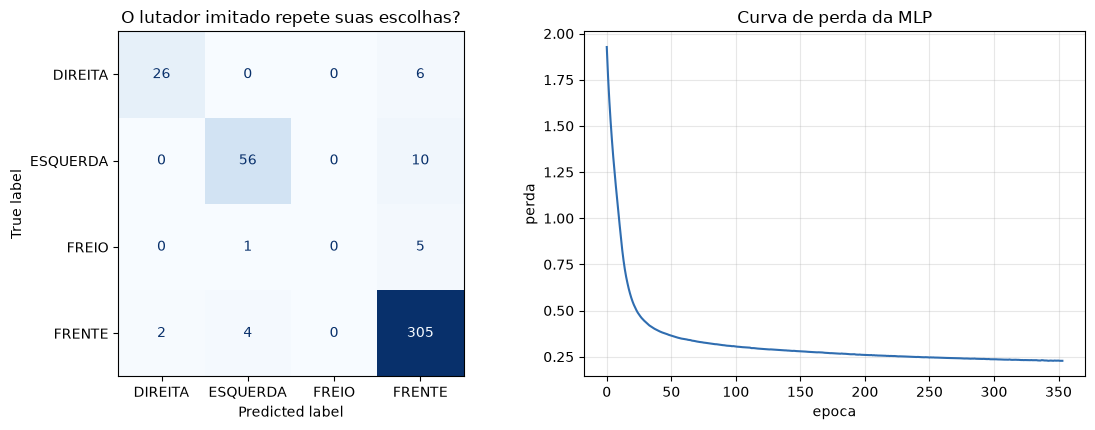

Lutador salvo em lutador_equipe.joblib


In [3]:
import joblib
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

dados = pd.read_csv(ARQUIVO_DADOS)
dados_treino = dados.loc[dados["acao"] != "PARAR"].copy()
colunas_entrada = [f"raio{i}" for i in range(5)] + ["vel", "bearing", "dist_inimigo", "dist_centro"]
print("Lutas gravadas:", dados["luta"].nunique(), "| amostras:", len(dados))
print("Acoes usadas no treino:", dados_treino["acao"].value_counts().to_dict())

X = dados_treino[colunas_entrada]
y = dados_treino["acao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
lutador = Pipeline([
    ("escala", StandardScaler()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=600, random_state=42)),
])
lutador.fit(X_treino, y_treino)
predicao = lutador.predict(X_teste)
acuracia = accuracy_score(y_teste, predicao)
ficha["acuracia_imitacao"] = round(float(acuracia), 4)
print(f"Acuracia da imitacao: {acuracia:.2%}")
print(classification_report(y_teste, predicao, zero_division=0))

figura, eixos = plt.subplots(1, 2, figsize=(11.5, 4.4))
ConfusionMatrixDisplay.from_predictions(y_teste, predicao, cmap="Blues", ax=eixos[0], colorbar=False)
eixos[0].set_title("O lutador imitado repete suas escolhas?")
eixos[1].plot(lutador.named_steps["mlp"].loss_curve_, color="#2f6db0")
eixos[1].set_title("Curva de perda da MLP")
eixos[1].set_xlabel("epoca")
eixos[1].set_ylabel("perda")
eixos[1].grid(alpha=0.3)
figura.tight_layout()
figura.savefig("entregas/imitacao_matriz_e_perda.png", dpi=150)
plt.show()

joblib.dump(lutador, "lutador_equipe.joblib")
print("Lutador salvo em lutador_equipe.joblib")


## 4. Soltar o lutador ao vivo

A IA luta sozinha: a cada ciclo le sensores, consulta a rede e envia a acao. Meça a latencia — e o mesmo conceito da Aula 6, agora em combate.

In [4]:
EXECUTAR_LUTADOR = True

if EXECUTAR_LUTADOR:
    latencias = []
    acoes_escolhidas = []
    ultima_acao = None
    estado = esperar_largada(cliente)
    prazo = time.time() + 100
    while time.time() < prazo and estado["vencedor"] is None:
        entrada = pd.DataFrame([features(estado)], columns=colunas_entrada)
        acao = lutador.predict(entrada)[0]
        if acao != ultima_acao:
            print(f"Acao da IA: {acao}")
            ultima_acao = acao
        acoes_escolhidas.append(acao)
        t0 = time.perf_counter()
        estado = cliente.enviar(acao)
        latencias.append((time.perf_counter() - t0) * 1000)
        time.sleep(0.02)
    ficha["latencia_media_ms"] = round(float(np.mean(latencias)), 1)
    ficha["latencia_p95_ms"] = round(float(np.percentile(latencias, 95)), 1)
    print(f"Vencedor: {estado['vencedor']} | caiu: {estado['caiu']} | duracao: {estado['t']}s")
    print(f"Latencia media: {np.mean(latencias):.1f} ms | p95: {np.percentile(latencias, 95):.1f} ms")
    print("Acoes escolhidas:", pd.Series(acoes_escolhidas).value_counts().to_dict())
    if acoes_escolhidas and set(acoes_escolhidas) == {"PARAR"}:
        print("O modelo escolheu apenas PARAR. Volte a etapa 2 e colete mais exemplos com as setas pressionadas antes de treinar novamente.")
else:
    print("Altere EXECUTAR_LUTADOR para True e veja sua IA lutar.")


Acao da IA: FRENTE


Acao da IA: DIREITA
Vencedor: A | caiu: B | duracao: 6.2s
Latencia media: 10.6 ms | p95: 12.6 ms
Acoes escolhidas: {np.str_('FRENTE'): 85, np.str_('DIREITA'): 6}


## 5. Torneio classificatorio contra o bot

Para ganhar vaga na Copa, venca o robo B em **2 de 3 lutas**. Rode a celula e registre o placar. Perdeu? Volte a teleoperar: colete lutas atacando nos momentos em que o bot hesita e evitando a borda.

In [5]:
EXECUTAR_TORNEIO = True

if EXECUTAR_TORNEIO:
    placar = {"IA": 0, "BOT": 0}
    linhas = []
    for luta in range(1, 4):
        estado = esperar_largada(cliente)
        prazo = time.time() + 100
        while time.time() < prazo and estado["vencedor"] is None:
            entrada = pd.DataFrame([features(estado)], columns=colunas_entrada)
            estado = cliente.enviar(lutador.predict(entrada)[0])
        vencedor = estado["vencedor"]
        if vencedor == "A":
            placar["IA"] += 1
        elif vencedor == "B":
            placar["BOT"] += 1
        linhas.append({"luta": luta, "vencedor": vencedor, "caiu": estado["caiu"], "duracao_s": estado["t"]})
        print(f"Luta {luta}: vencedor {vencedor} | caiu {estado['caiu']} | t {estado['t']}s")
    pd.DataFrame(linhas).to_csv("entregas/torneio_vs_bot.csv", index=False)
    ficha["torneio_vs_bot"] = f"{placar['IA']} x {placar['BOT']}"
    ficha["torneio_vencido"] = bool(placar["IA"] >= 2)
    print("Placar final:", placar)
else:
    print("Altere EXECUTAR_TORNEIO para True para disputar 2 de 3 contra o bot.")


Luta 1: vencedor A | caiu B | t 6.23s


Luta 2: vencedor A | caiu B | t 6.1s


Luta 3: vencedor A | caiu B | t 6.17s
Placar final: {'IA': 3, 'BOT': 0}


## 6. Analisar: por que as lutas foram assim?

Classifique cada amostra da sua coleta: o lutador estava **atacando** (perto do inimigo) ou **em risco** (perto da borda)? A pergunta que vale pontos: suas derrotas vieram de excesso de agressividade ou de excesso de medo?

In [6]:
dados["zona"] = np.select(
    [dados["dist_centro"] > 0.7, dados["dist_inimigo"] < 0.15],
    ["risco_borda", "combate"],
    default="manobra",
)
resumo = dados.groupby("zona").agg(
    amostras=("acao", "count"),
    frente_pct=("acao", lambda s: (s == "FRENTE").mean()),
)
display(resumo.round(3))
resumo.round(4).to_csv("entregas/analise_zonas.csv")
if "risco_borda" in resumo.index:
    ficha["frente_na_borda"] = round(float(resumo.loc["risco_borda", "frente_pct"]), 3)
print("Se risco_borda tem muitas amostras de FRENTE, seu lutador e suicida.")


,amostras,frente_pct
zona,,
combate,1127,0.783
manobra,210,0.933
risco_borda,322,0.509


Se risco_borda tem muitas amostras de FRENTE, seu lutador e suicida.


## 7. COPA (obrigatoria)

Todo grupo compete. Receba o `lutador_rival.joblib` de outra equipe: sua IA fica no robo A, a do rival no B. Melhor de 3. A Copa so abre quando o torneio contra o bot estiver vencido.

In [7]:
EXECUTAR_COPA = True

if EXECUTAR_COPA:
    lutador_b = joblib.load("lutador_rival.joblib")
    cliente_a = ClienteArena(robot="A", timeout=5.0)
    cliente_b = ClienteArena(robot="B", timeout=5.0)
    cliente_a.conectar(); cliente_b.conectar()
    placar = {"A": 0, "B": 0}
    linhas = []
    for luta in range(1, 4):
        cliente_a.enviar(cmd="RESET")
        while cliente_a.enviar("PARAR")["fase"] == "CONTAGEM":
            cliente_b.enviar("PARAR")
            time.sleep(0.15)
        estado_a, estado_b = cliente_a.ultimo_estado, cliente_b.ultimo_estado
        prazo = time.time() + 100
        while time.time() < prazo and estado_a["vencedor"] is None:
            entrada_a = pd.DataFrame([features(estado_a)], columns=colunas_entrada)
            entrada_b = pd.DataFrame([features(estado_b)], columns=colunas_entrada)
            estado_a = cliente_a.enviar(lutador.predict(entrada_a)[0])
            estado_b = cliente_b.enviar(lutador_b.predict(entrada_b)[0])
        if estado_a["vencedor"]:
            placar[estado_a["vencedor"]] += 1
        linhas.append({"luta": luta, "vencedor": estado_a["vencedor"],
                       "caiu": estado_a["caiu"], "duracao_s": estado_a["t"]})
        print(f"Luta {luta}: venceu {estado_a['vencedor']} | caiu {estado_a['caiu']}")
    pd.DataFrame(linhas).to_csv("entregas/copa.csv", index=False)
    ficha["copa"] = f"{placar['A']} x {placar['B']}"
    print("Copa:", placar)
    cliente_a.fechar(); cliente_b.fechar()
else:
    print("Receba o lutador rival e altere EXECUTAR_COPA para True.")

with open("entregas/ficha_copa.json", "w", encoding="utf-8") as saida:
    json.dump(ficha, saida, indent=2, ensure_ascii=False)
print("Ficha da Copa:", json.dumps(ficha, indent=2, ensure_ascii=False))


Luta 1: venceu A | caiu B


Luta 2: venceu A | caiu B


Luta 3: venceu A | caiu B
Copa: {'A': 3, 'B': 0}
Ficha da Copa: {
  "amostras": 1659,
  "lutas_gravadas": 6,
  "acuracia_imitacao": 0.9325,
  "latencia_media_ms": 10.6,
  "latencia_p95_ms": 12.6,
  "torneio_vs_bot": "3 x 0",
  "torneio_vencido": true,
  "frente_na_borda": 0.509,
  "copa": "3 x 0"
}


## Do simulador para o fisico

- **entrada**: raios, posicao do adversario, distancia do centro — no carrinho real, sensores de distancia e visao;
- **saida**: FRENTE, ESQUERDA, DIREITA, PARAR — no carrinho real, comandos aos motores;
- **protocolo**: TCP+JSON com a arena; serial com o Arduino.

O cerebro viaja. O corpo troca. O contrato permanece.

## Ficha da Copa e entrega

| Item | Valor |
|---|---|
| Amostras de teleoperacao | |
| Acuracia da imitacao | |
| Torneio vs bot (2 de 3?) | |
| Latencia media | |
| Copa: vitorias/derrotas | |
| Causa das derrotas (agressivo x medroso) | |

- [ ] Conexao e sensores testados.
- [ ] 300+ amostras em pelo menos 3 lutas.
- [ ] Imitacao com 85%+.
- [ ] Torneio contra o bot vencido (2 de 3).
- [ ] Copa disputada.
- [ ] Analise agressividade x risco documentada.
- [ ] Resposta: o que muda para o carrinho fisico?